In [1]:
print("Hello! This is my first data analysis project.")

Hello! This is my first data analysis project.


In [2]:
from google.colab import files

uploaded = files.upload()

Saving Mean_Seasonal_IMD_2017.csv to Mean_Seasonal_IMD_2017.csv


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import os

print(os.listdir())

['.config', 'Mean_Seasonal_IMD_2017.csv', 'sample_data']


In [5]:
df = pd.read_csv("Mean_Seasonal_IMD_2017.csv")

print(df.head())
print(df.columns.tolist())
print(df.shape)

   YEAR  ANNUAL  JAN-FEB  MAR-MAY  JUN-SEP  OCT-DEC
0  1901   24.23    18.71    26.06    27.30    21.92
1  1902   24.33    19.70    26.44    27.18    21.49
2  1903   23.80    19.05    25.47    27.17    21.27
3  1904   23.86    18.66    25.84    26.83    21.42
4  1905   23.71    17.58    24.99    27.37    21.48
['YEAR', 'ANNUAL', 'JAN-FEB', 'MAR-MAY', 'JUN-SEP', 'OCT-DEC']
(117, 6)


In [6]:
# Remove extra spaces from column names
df.columns = df.columns.str.strip()

# Keep only year and annual temperature
df = df[["YEAR", "ANNUAL"]].copy()

# Convert values to numbers
df["YEAR"] = pd.to_numeric(df["YEAR"], errors="coerce")
df["ANNUAL"] = pd.to_numeric(df["ANNUAL"], errors="coerce")

# Remove missing values and duplicate years
df = df.dropna(subset=["YEAR", "ANNUAL"])
df = df.drop_duplicates(subset=["YEAR"])

# Sort data by year
df = df.sort_values("YEAR")

print(df.head())
print("Total years:", len(df))

   YEAR  ANNUAL
0  1901   24.23
1  1902   24.33
2  1903   23.80
3  1904   23.86
4  1905   23.71
Total years: 117


In [7]:
df = df[
    (df["YEAR"] >= 1968) &
    (df["YEAR"] <= 2017)
].copy()

df = df.sort_values("YEAR").reset_index(drop=True)

print("First year:", df["YEAR"].min())
print("Last year:", df["YEAR"].max())
print("Number of years:", len(df))

First year: 1968
Last year: 2017
Number of years: 50


In [8]:
# Calculate the average temperature for the selected period
reference_average = df["ANNUAL"].mean()

# Calculate temperature anomaly for each year
df["ANOMALY"] = df["ANNUAL"] - reference_average

print("Reference average:", round(reference_average, 2), "°C")
print(df[["YEAR", "ANNUAL", "ANOMALY"]].head())

Reference average: 24.55 °C
   YEAR  ANNUAL  ANOMALY
0  1968   23.94  -0.6116
1  1969   24.46  -0.0916
2  1970   24.26  -0.2916
3  1971   23.91  -0.6416
4  1972   24.10  -0.4516


In [9]:
df["Rolling_10_Year"] = (
    df["ANNUAL"].rolling(window=10).mean()
)

print(df[["YEAR", "ANNUAL", "Rolling_10_Year"]].tail(15))

    YEAR  ANNUAL  Rolling_10_Year
35  2003   24.72           24.688
36  2004   24.74           24.716
37  2005   24.58           24.645
38  2006   25.06           24.696
39  2007   24.77           24.763
40  2008   24.61           24.748
41  2009   25.11           24.792
42  2010   25.13           24.845
43  2011   24.67           24.839
44  2012   24.69           24.808
45  2013   24.82           24.818
46  2014   24.73           24.817
47  2015   24.91           24.850
48  2016   26.45           24.989
49  2017   26.29           25.141


In [10]:
top_5 = (
    df.assign(Absolute_Anomaly=df["ANOMALY"].abs())
      .nlargest(5, "Absolute_Anomaly")
      .sort_values("ANOMALY")
)

print(
    top_5[["YEAR", "ANNUAL", "ANOMALY"]]
    .round(2)
    .to_string(index=False)
)

 YEAR  ANNUAL  ANOMALY
 1975   23.74    -0.81
 1971   23.91    -0.64
 1995   25.29     0.74
 2017   26.29     1.74
 2016   26.45     1.90


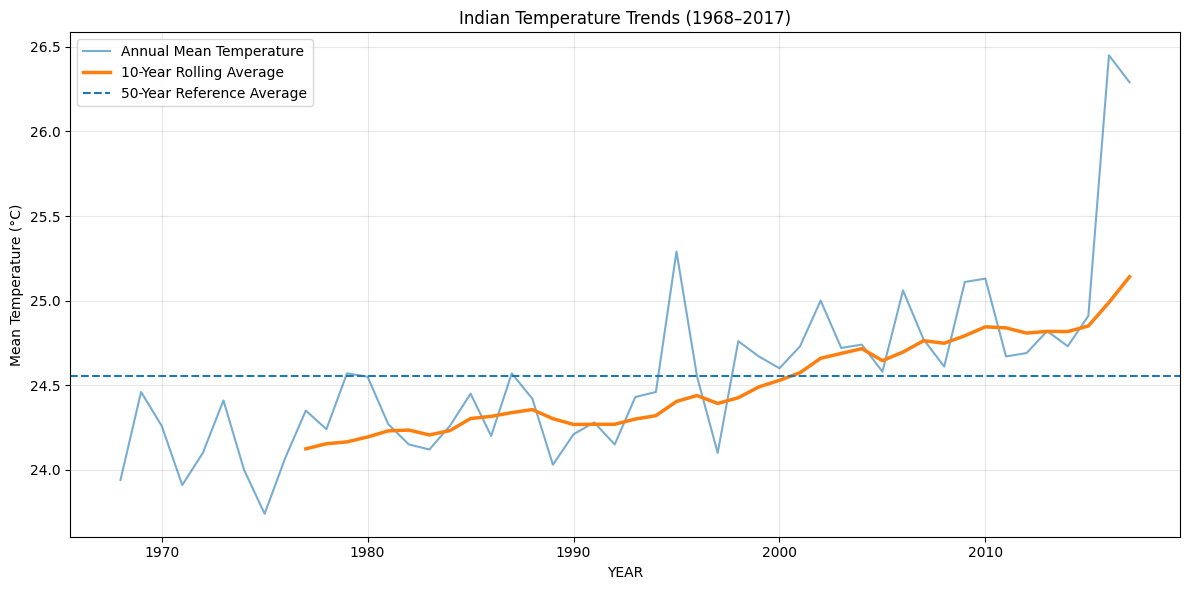

In [11]:
plt.figure(figsize=(12, 6))

plt.plot(
    df["YEAR"],
    df["ANNUAL"],
    label="Annual Mean Temperature",
    alpha=0.6
)

plt.plot(
    df["YEAR"],
    df["Rolling_10_Year"],
    label="10-Year Rolling Average",
    linewidth=2.5
)

plt.axhline(
    reference_average,
    linestyle="--",
    label="50-Year Reference Average"
)

plt.title("Indian Temperature Trends (1968–2017)")
plt.xlabel("YEAR")
plt.ylabel("Mean Temperature (°C)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

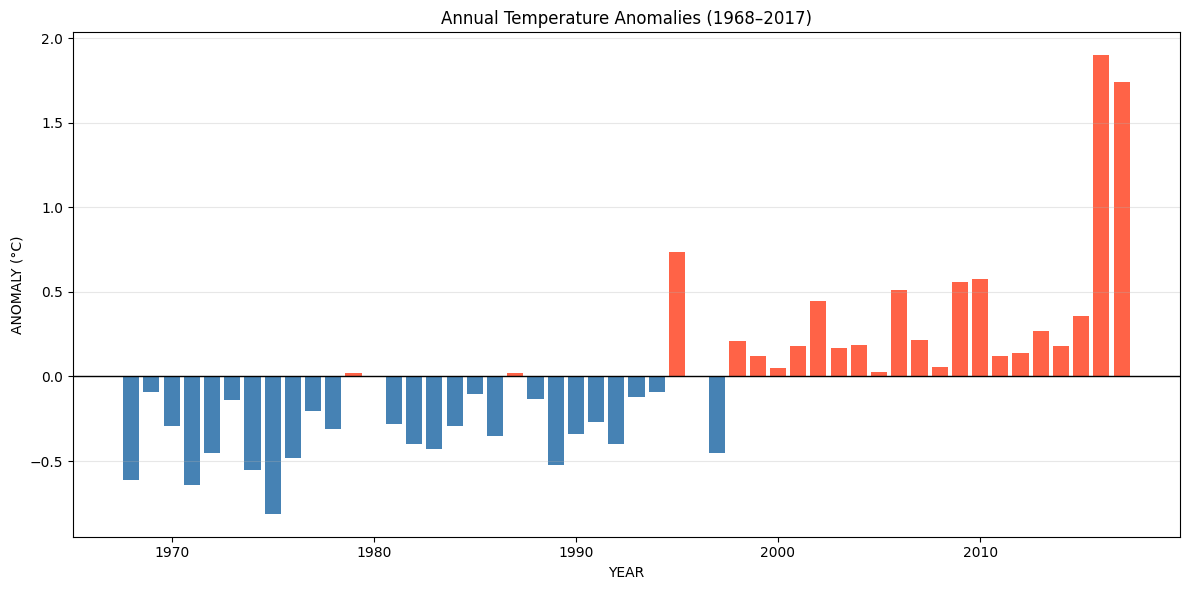

In [12]:
plt.figure(figsize=(12, 6))

colors = np.where(df["ANOMALY"] >= 0, "tomato", "steelblue")

plt.bar(df["YEAR"], df["ANOMALY"], color=colors)

plt.axhline(0, color="black", linewidth=1)
plt.title("Annual Temperature Anomalies (1968–2017)")
plt.xlabel("YEAR")
plt.ylabel("ANOMALY (°C)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [13]:
print(round(reference_average, 2))

24.55


In [14]:
print(top_5[["YEAR", "ANOMALY"]].round(2))

    YEAR  ANOMALY
7   1975    -0.81
3   1971    -0.64
27  1995     0.74
49  2017     1.74
48  2016     1.90


## Key Findings

1. **Study Period:** The analysis covers the years 1968 to 2017, representing a 50-year period of Indian temperature data.

2. **Average Temperature:** The average annual temperature during this period was **24.5 °C**.

3. **Long-Term Trend:** The 10-year rolling average shows **the trend generally increases** over the study period.

4. **Extreme Anomalies:** The five most extreme temperature anomalies were observed in **1975,1971,1995,2017,2016**. The largest positive anomaly was **1.90°C**, while the largest negative anomaly was **0.64 °C**.

5. **Conclusion:** This analysis helps identify long-term temperature patterns and unusually warm or cool years using historical data.